# Prerequisite 04 · 数学与概率：只补 RL 必需部分

[上一章：Matplotlib](Prerequisite03_Matplotlib.ipynb) · [下一章：概率与采样](Prerequisite04B_Probability.ipynb)

**目标：**理解向量、矩阵、期望、方差、导数、链式法则、log、softmax 和交叉熵，不追求严格数学证明。


## 1. 向量、矩阵与加权和

神经网络线性层是 $y=xW+b$；离散期望是加权和 $\mathbb E[X]=\sum_xp(x)x$。Bellman 方程也是“奖励 + 下一状态价值的概率加权和”。


In [1]:
import numpy as np

x = np.array([2.0, -1.0])
W = np.array([[1.0, .5, -.2], [.3, -1.0, .8]])
b = np.array([.1, .2, .3])
print("linear output:", x @ W + b)

outcomes = np.array([-1.0, 0.0, 2.0])
probabilities = np.array([.2, .5, .3])
expectation = np.sum(probabilities * outcomes)
variance = np.sum(probabilities * (outcomes - expectation)**2)
print("E[X], Var[X]:", expectation, variance)


linear output: [ 1.8  2.2 -0.9]
E[X], Var[X]: 0.39999999999999997 1.2400000000000002


## 2. 导数与链式法则

导数描述“参数微小变化让目标怎样变化”。若 $a=wx$、$L=(a-y)^2$：

$$\frac{\partial L}{\partial w}=2(a-y)x$$

这就是把 $\partial L/\partial a$ 与 $\partial a/\partial w$ 相乘。深度学习的反向传播只是对大型计算图重复链式法则。


In [2]:
x, y, w = 3.0, 7.0, 1.5
analytic = 2 * (w*x - y) * x
eps = 1e-5
loss = lambda weight: (weight*x - y)**2
numeric = (loss(w+eps) - loss(w-eps)) / (2*eps)
print("analytic / numerical gradient:", analytic, numeric)
assert abs(analytic - numeric) < 1e-6


analytic / numerical gradient: -15.0 -15.000000000320311


## 3. log、softmax 与交叉熵

softmax 把 logits 变成和为 1 的概率：

$$p_i=\frac{e^{z_i}}{\sum_j e^{z_j}}$$

为数值稳定先减去最大 logit。分类交叉熵 $-\log p_y$ 会强烈惩罚给正确类别极低概率；策略梯度中的 `log_prob` 也来自对概率乘积取 log。


In [3]:
logits = np.array([2.0, 1.0, -1.0])
stable = logits - logits.max()
probs = np.exp(stable) / np.exp(stable).sum()
target = 0
cross_entropy = -np.log(probs[target])
print("probabilities:", np.round(probs, 4), "sum:", probs.sum())
print("cross-entropy:", round(cross_entropy, 4))


probabilities: [0.7054 0.2595 0.0351] sum: 1.0000000000000002
cross-entropy: 0.349


## 4. 矩阵乘法一步步算（第一次接触请务必手算）

$C=AB$ 中，$C_{ij}$ = **A 的第 i 行**与 **B 的第 j 列**逐项相乘再求和。所以 A 的列数必须等于 B 的行数：
`(m, n) @ (n, p) → (m, p)`。

在神经网络里：每一行是一个样本，每一列是一个特征；`X @ W` 就是“每个样本对每个输出神经元做一次加权求和”。
下面用循环和 `@` 各算一次，确认二者一致。


In [4]:
import numpy as np

A = np.array([[1., 2., 3.],
              [4., 5., 6.]])          # (2, 3)：2 个样本，3 个特征
B = np.array([[1., 0.],
              [0., 1.],
              [1., 1.]])              # (3, 2)：3 个输入 → 2 个输出
C_loop = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        C_loop[i, j] = sum(A[i, k] * B[k, j] for k in range(3))
print("循环结果:\n", C_loop)
print("A @ B:\n", A @ B)
assert np.allclose(C_loop, A @ B)


循环结果:
 [[ 4.  5.]
 [10. 11.]]
A @ B:
 [[ 4.  5.]
 [10. 11.]]


## 5. 多变量函数的梯度：指向“上坡最陡”的方向

对 $f(w_1,w_2)$，梯度 $\nabla f=(\partial f/\partial w_1,\ \partial f/\partial w_2)$ 是一个向量，指向函数增长最快的方向。
梯度下降沿 **负梯度** 走一小步，函数值就会下降。下面在等高线图上画出梯度下降的轨迹。


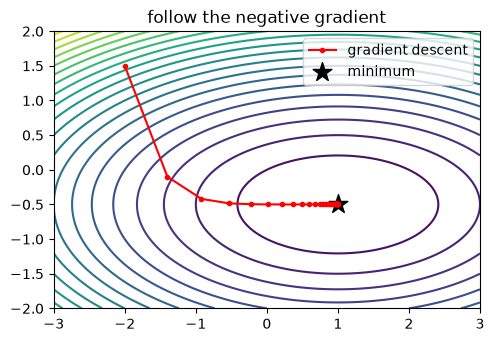

终点: [ 0.9963 -0.5   ]  f = 1.4e-05


In [5]:
import matplotlib.pyplot as plt

f = lambda w: (w[0] - 1) ** 2 + 4 * (w[1] + 0.5) ** 2
grad = lambda w: np.array([2 * (w[0] - 1), 8 * (w[1] + 0.5)])

w = np.array([-2.0, 1.5]); path = [w.copy()]
for _ in range(30):
    w = w - 0.1 * grad(w)
    path.append(w.copy())
path = np.array(path)

g1, g2 = np.meshgrid(np.linspace(-3, 3, 100), np.linspace(-2, 2, 100))
plt.figure(figsize=(5.5, 3.6))
plt.contour(g1, g2, (g1 - 1) ** 2 + 4 * (g2 + 0.5) ** 2, levels=20, cmap="viridis")
plt.plot(path[:, 0], path[:, 1], "o-", color="red", markersize=3, label="gradient descent")
plt.scatter([1], [-0.5], marker="*", s=200, color="black", label="minimum")
plt.legend(); plt.title("follow the negative gradient"); plt.show(); plt.close()
print("终点:", np.round(path[-1], 4), " f =", round(f(path[-1]), 6))


## 自动批改练习

每道题先读题、再写代码、最后运行同一格。看到 `[通过]` 才算完成；`[未通过]` 会说明哪里不对。
参考答案默认折叠，建议独立尝试至少 10 分钟后再看。


In [6]:
# 自动检查工具：每道练习末尾都会调用 check(test_xxx)。
# 未完成或有错时只打印提示，不会中断 Run All。
def check(test):
    try:
        test()
    except NotImplementedError:
        print(f"[未完成] {test.__name__}：把 raise NotImplementedError 换成你的代码，再运行本格。")
    except AssertionError as error:
        print(f"[未通过] {test.__name__}：{error}")
    except Exception as error:  # 代码本身报错，也给出可读提示
        print(f"[代码报错] {test.__name__}：{type(error).__name__}: {error}")
    else:
        print(f"[通过] {test.__name__}")


### 练习 1：矩阵乘法的 shape

实现 `matmul_shape(a, b)`：输入两个二维 shape 元组，可相乘时返回结果 shape，不可相乘时返回 `None`。不要真的创建数组。


In [7]:
def matmul_shape(a, b):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_matmul_shape():
    assert matmul_shape((32, 4), (4, 2)) == (32, 2), "(B,F)@(F,A) → (B,A)"
    assert matmul_shape((32, 4), (2, 4)) is None, "内维 4 和 2 不同，不能相乘"
    assert matmul_shape((1, 512), (512, 6)) == (1, 6)

check(test_matmul_shape)


[未完成] test_matmul_shape：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
def matmul_shape(a, b):
    return (a[0], b[1]) if a[1] == b[0] else None
```

</details>


### 练习 2：数值稳定的 softmax

实现 `softmax(logits)`：支持一维或二维输入（二维时对最后一维计算）。`logits=[1000, 1000]` 时也必须返回 `[0.5, 0.5]`。

<details><summary>提示（卡住 10 分钟再看）</summary>

减去最大值：`z = logits - logits.max(axis=-1, keepdims=True)`。

</details>


In [8]:
import numpy as np

def softmax(logits):
    logits = np.asarray(logits, dtype=float)
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
import numpy as np

def test_softmax():
    assert np.allclose(softmax([1000.0, 1000.0]), [0.5, 0.5]), "大 logits 也不能溢出"
    p = softmax(np.array([[1.0, 2.0, 3.0], [0.0, 0.0, 0.0]]))
    assert p.shape == (2, 3) and np.allclose(p.sum(axis=1), 1.0), "二维输入应对每一行归一化"
    assert np.allclose(p[1], 1 / 3), "logits 全相同时概率应均匀"

check(test_softmax)


[未完成] test_softmax：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
import numpy as np

def softmax(logits):
    logits = np.asarray(logits, dtype=float)
    z = logits - logits.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)
```

</details>


### 练习 3：每一步的折扣回报

实现 `discounted_returns(rewards, gamma)`，返回与 `rewards` 等长的列表，第 t 项是
$G_t=r_t+\gamma r_{t+1}+\gamma^2 r_{t+2}+\dots$。策略梯度（Chapter11）就需要每一步的 $G_t$。

<details><summary>提示（卡住 10 分钟再看）</summary>

从后往前：`G = r + gamma * G`，每步把 G 放进结果，最后反转。

</details>


In [9]:
def discounted_returns(rewards, gamma):
    raise NotImplementedError


# ---- 自动检查（不用修改） ----
def test_discounted_returns():
    out = discounted_returns([0.0, 0.0, 1.0], 0.9)
    assert len(out) == 3, "长度应与 rewards 相同"
    assert all(abs(a - b) < 1e-9 for a, b in zip(out, [0.81, 0.9, 1.0])), f"应为 [0.81, 0.9, 1.0]，得到 {out}"
    assert discounted_returns([1.0, 1.0], 0.0) == [1.0, 1.0], "gamma=0 时只看即时奖励"

check(test_discounted_returns)


[未完成] test_discounted_returns：把 raise NotImplementedError 换成你的代码，再运行本格。


<details><summary>参考答案（先独立完成，再对照）</summary>

```python
def discounted_returns(rewards, gamma):
    G, out = 0.0, []
    for r in reversed(rewards):
        G = r + gamma * G
        out.append(G)
    return out[::-1]
```

</details>


## 练习与过关标准

**练习：**手算分布 `[0.25, 0.75]` 上变量 `[0, 2]` 的期望和方差；解释为什么方差不是“平均误差”。

<details><summary>答案</summary>期望为 1.5；方差为 $0.25(0-1.5)^2+0.75(2-1.5)^2=0.75$。</details>

**过关：**能读懂矩阵乘法的 shape；能用期望解释随机回报；能说出梯度符号决定更新方向；能计算 softmax 与 cross-entropy。
